In [50]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from joblib import load, dump
import random
import seaborn as sns
import ast
from collections import Counter

## Getting the data

In [29]:
transcriptomics = pd.read_csv(r'data\transcriptomics_filtered.csv')

In [51]:
transcriptomics = load(r'data/transcriptomics_filtered.joblib')
print(transcriptomics.shape)

(369, 25995)


In [52]:
transcriptomics.columns

Index(['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A4GALT', 'AAAS',
       'AACS', 'AACSP1',
       ...
       'ZWILCH', 'ZWINT', 'ZXDA', 'ZXDB', 'ZXDC', 'ZYG11A', 'ZYG11B', 'ZYX',
       'ZZEF1', 'ZZZ3'],
      dtype='object', length=25995)

In [53]:
folder_path = 'data\high_corr1'

In [54]:
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

Concatenate the datasets and add also a column with the number of features selected for that sample

In [61]:
dataframes = []

# Loop through the list of CSV files and read each one into a DataFrame
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    
    # Calculate feature_count and hyphen_count for the first row
    first_row_features = ast.literal_eval(df['selected_features_union'].iloc[0])  # Convert string to list
    feature_count = len(set(first_row_features))  # Count unique gene names

    print("Unique feature count:", feature_count)
  # Length of the list
    
    # Add columns with the same values for all rows
    df['feature_count'] = feature_count    
    # Append the DataFrame to the list
    dataframes.append(df)

# Concatenate all DataFrames vertically
enet_results = pd.concat(dataframes, ignore_index=True)
# Checking for features not in transcriptomics.columns
#all_selected_features = set(enet_results['selected_features_union'].explode())  # Flatten lists
#missing_features = all_selected_features - set(transcriptomics.columns)

# Print missing features
#print("Features in CSVs but not in transcriptomics.columns:")
#print(missing_features)
# Check the result
enet_results

Unique feature count: 14805
Unique feature count: 6613
Unique feature count: 12499
Unique feature count: 16091
Unique feature count: 16610
Unique feature count: 12081
Unique feature count: 14226
Unique feature count: 12551
Unique feature count: 8734
Unique feature count: 10656
Unique feature count: 12727
Unique feature count: 8785
Unique feature count: 14209
Unique feature count: 11684
Unique feature count: 14910
Unique feature count: 11491
Unique feature count: 14078
Unique feature count: 16689
Unique feature count: 13457
Unique feature count: 14573
Unique feature count: 15834
Unique feature count: 14280
Unique feature count: 11516
Unique feature count: 12774
Unique feature count: 11055
Unique feature count: 14693
Unique feature count: 12056
Unique feature count: 8755
Unique feature count: 17426
Unique feature count: 12010
Unique feature count: 12373
Unique feature count: 16124
Unique feature count: 10536
Unique feature count: 16599
Unique feature count: 16725
Unique feature count: 12

,protein,LOO sample,true,predicted,params,selected_features_union,feature_count
0,ACSL5,MDAMB468_BREAST,-0.126338,-0.454084,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805
1,ACSL5,SH4_SKIN,0.244245,-0.028952,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805
2,ACSL5,AU565_BREAST,1.970621,1.397700,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805
3,ACSL5,KMRC1_KIDNEY,-0.497596,-0.412958,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805
4,ACSL5,CAL51_BREAST,-0.932798,-1.132414,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805
...,...,...,...,...,...,...,...
89662,ZNF185,FADU_UPPER_AERODIGESTIVE_TRACT,0.543682,0.655607,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1', '...",16047
89663,ZNF185,KP4_PANCREAS,1.715237,-0.112982,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1', '...",16047
89664,ZNF185,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.674105,-1.398507,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1', '...",16047
89665,ZNF185,OVCAR8_OVARY,2.024517,0.544594,"{'alpha': 0.3, 'l1_ratio': 0.5, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1', '...",16047


### Sanity check for high correlated proteins

In [62]:
not_found_proteins = []
not_found_loo_samples = []

for index, row in enet_results.iterrows():
    protein_name = row['protein']
    loo_sample = row['LOO sample']
    selected_features = row['selected_features_union']
    
    if protein_name not in selected_features:
        not_found_proteins.append(protein_name)
        not_found_loo_samples.append(loo_sample)
        print(f"The protein name '{protein_name}' is not present in the 'selected_features_union' list for row {index} (LOO sample: {loo_sample}).")

# Check if lists are empty and print accordingly
if not not_found_proteins:
    print("\nNone of the highly correlated proteins are missing their corresponding gene in the selected features.")
else:
    print("\nProtein names that are not present in the 'selected_features_union' list:")
    print(", ".join(set(not_found_proteins)))

    print("\nLOO samples for which the protein name is not present in the 'selected_features_union' list:")
    print(", ".join(set(not_found_loo_samples)))


None of the highly correlated proteins are missing their corresponding gene in the selected features.


In [63]:
errors = (enet_results['true'] - enet_results['predicted']).abs()

In [64]:
enet_results['error'] = errors
del errors

In [65]:
enet_results.head()

,protein,LOO sample,true,predicted,params,selected_features_union,feature_count,error
0,ACSL5,MDAMB468_BREAST,-0.126338,-0.454084,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805,0.327747
1,ACSL5,SH4_SKIN,0.244245,-0.028952,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805,0.273197
2,ACSL5,AU565_BREAST,1.970621,1.397700,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805,0.572921
3,ACSL5,KMRC1_KIDNEY,-0.497596,-0.412958,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805,0.084639
4,ACSL5,CAL51_BREAST,-0.932798,-1.132414,"{'alpha': 0.1, 'l1_ratio': 0.9, 'p_value': 0.0...","['A1BG', 'A1BG-AS1', 'A1CF', 'A2ML1', 'AAAS', ...",14805,0.199616


## MAEs

In [66]:
maes = enet_results[['protein', 'error']].groupby('protein').mean()
maes.head()

,error
protein,
ACSL5,0.606279
ACTL8,0.611986
ADIRF,1.136266
AGR2,0.855728
AHNAK2,0.696209


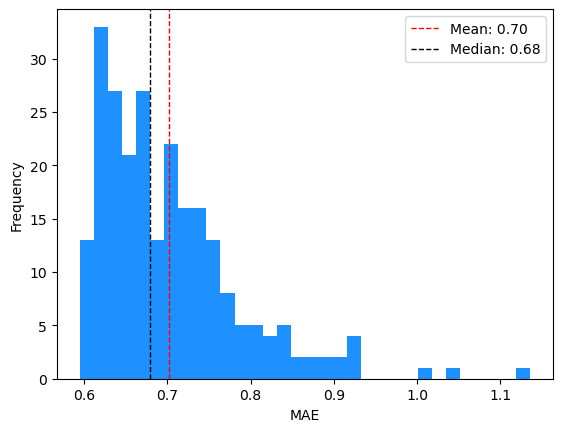

In [67]:
mean_value = maes.mean()[0]
median_value = maes.median()[0]

# Plotting the histogram
plt.hist(maes, bins=32, color='dodgerblue')

# Adding vertical lines for mean and median
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')

# Adding titles and labels
plt.xlabel('MAE')
plt.ylabel('Frequency')
plt.legend()

# Display the plot
plt.show()

## MAE vs correlation

In [68]:
correlations = load('data\correlations.joblib')
correlations

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [69]:
protein_list = [prot for prot in maes.index if prot in correlations.index]
len(protein_list)

243

In [70]:
correlations_matched = correlations.reindex(protein_list)
maes_matched = maes.reindex(protein_list)

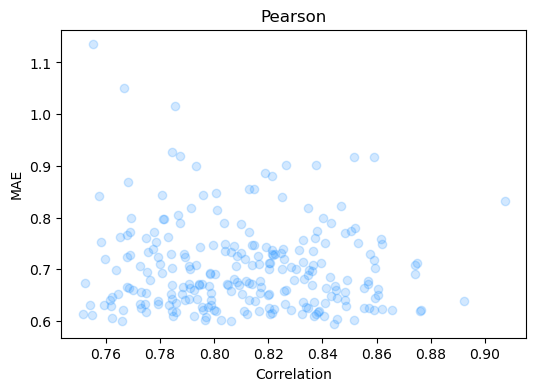

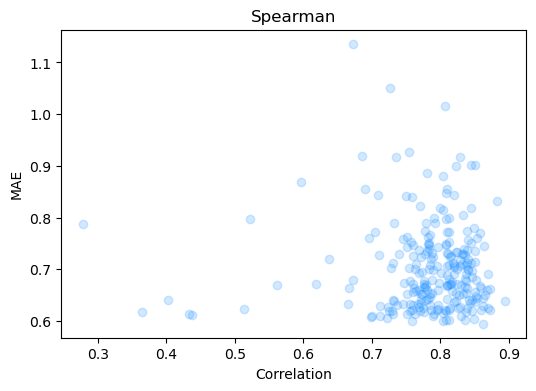

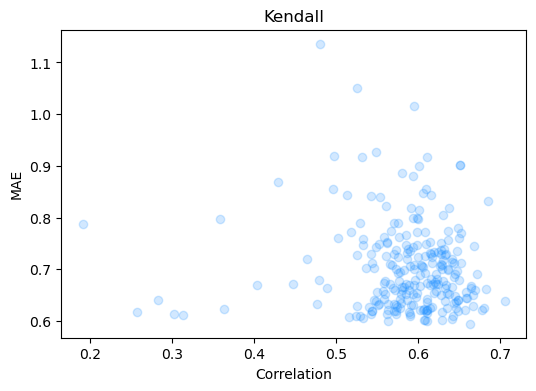

In [71]:
# pearson
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['pearson'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Pearson')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

# Scatter plot: Series 1 vs Series 3
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['spearman'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Spearman')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

# Scatter plot: Series 1 vs Series 4
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['kendall'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Kendall')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

## Best proteins

In [72]:
sorted_proteins = maes['error'].sort_values()
sorted_proteins

protein
ANXA6     0.594675
MYLK      0.599214
COBLL1    0.600830
SORL1     0.601302
ITGA5     0.601921
            ...   
SNCG      0.918350
CRIP1     0.927542
COL4A1    1.016062
CDA       1.049889
ADIRF     1.136266
Name: error, Length: 243, dtype: float64

In [73]:
sorted_proteins[:100]

protein
ANXA6       0.594675
MYLK        0.599214
COBLL1      0.600830
SORL1       0.601302
ITGA5       0.601921
              ...   
NT5E        0.663122
TSPAN6      0.663133
S100A13     0.663608
CRIP2       0.665016
MARCKSL1    0.665184
Name: error, Length: 100, dtype: float64

In [74]:
dump(sorted_proteins, 'data\high_corr1\sorted.joblib')
dump(sorted_proteins[:100], 'data\high_corr1\sorted100.joblib')
dump(maes, 'data\high_corr1\maes.joblib')

['data\\high_corr1\\maes.joblib']

## Sample-wise analysis

In [75]:
loo_maes = enet_results[['LOO sample', 'error']].groupby('LOO sample').mean()

In [76]:
loo_maes

,error
LOO sample,
22RV1_PROSTATE,0.640142
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.670933
769P_KIDNEY,0.812902
786O_KIDNEY,0.672088
8305C_THYROID,0.699487
...,...
WM1799_SKIN,0.470724
WM2664_SKIN,0.531977
WM793_SKIN,0.767058


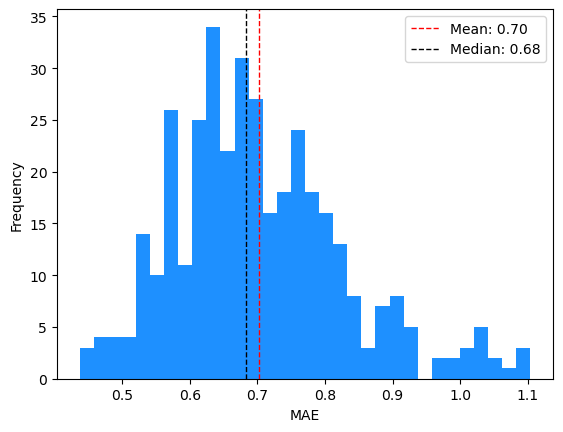

In [77]:
mean_value = loo_maes.mean()[0]
median_value = loo_maes.median()[0]

# Plotting the histogram
plt.hist(loo_maes, bins=32, color='dodgerblue')

# Adding vertical lines for mean and median
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')

# Adding titles and labels
plt.xlabel('MAE')
plt.ylabel('Frequency')
plt.legend()

# Display the plot
plt.show()

In [78]:
sorted_loos = loo_maes['error'].sort_values()
sorted_loos

LOO sample
PATU8988T_PANCREAS                  0.436716
SKHEP1_LIVER                        0.446647
IPC298_SKIN                         0.447631
TYKNU_OVARY                         0.457942
A2058_SKIN                          0.466596
                                      ...   
NUGC3_STOMACH                       1.058272
BICR22_UPPER_AERODIGESTIVE_TRACT    1.062721
IM95_STOMACH                        1.100719
NCIH1573_LUNG                       1.102187
SBC5_LUNG                           1.104261
Name: error, Length: 369, dtype: float64

In [79]:
dump(sorted_loos[:100], 'data\high_corr1\loos100.joblib')

['data\\high_corr1\\loos100.joblib']

## Tissue-specific analysis

In [80]:
loo_maes.head()

,error
LOO sample,
22RV1_PROSTATE,0.640142
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.670933
769P_KIDNEY,0.812902
786O_KIDNEY,0.672088
8305C_THYROID,0.699487


In [81]:
multi_idx = loo_maes.index.str.split('_', expand=True, n=1)
loo_maes.index = multi_idx
loo_maes.reset_index(inplace=True)
loo_maes.head()

,level_0,level_1,error
0,22RV1,PROSTATE,0.640142
1,697,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.670933
2,769P,KIDNEY,0.812902
3,786O,KIDNEY,0.672088
4,8305C,THYROID,0.699487


In [82]:
tissues = list(set(loo_maes['level_1']))
tissues

['THYROID',
 'AUTONOMIC_GANGLIA',
 'PROSTATE',
 'BONE',
 'LUNG',
 'HAEMATOPOIETIC_AND_LYMPHOID_TISSUE',
 'OVARY',
 'LARGE_INTESTINE',
 'STOMACH',
 'UPPER_AERODIGESTIVE_TRACT',
 'KIDNEY',
 'BILIARY_TRACT',
 'LIVER',
 'PLEURA',
 'URINARY_TRACT',
 'SKIN',
 'PANCREAS',
 'ENDOMETRIUM',
 'CENTRAL_NERVOUS_SYSTEM',
 'SOFT_TISSUE',
 'OESOPHAGUS',
 'BREAST']

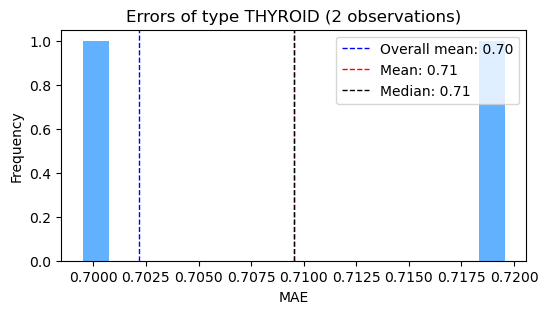

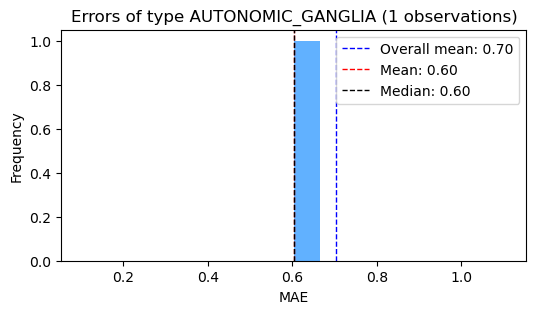

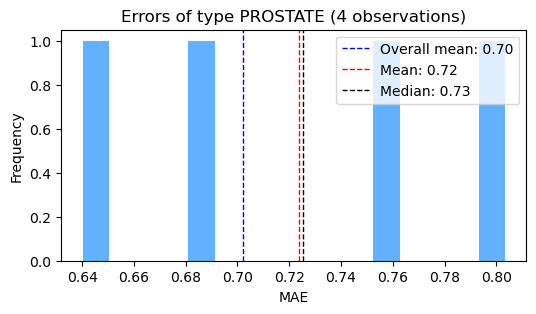

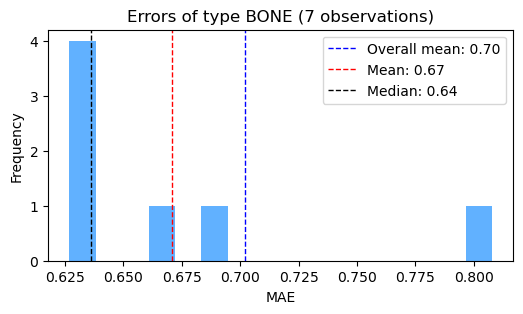

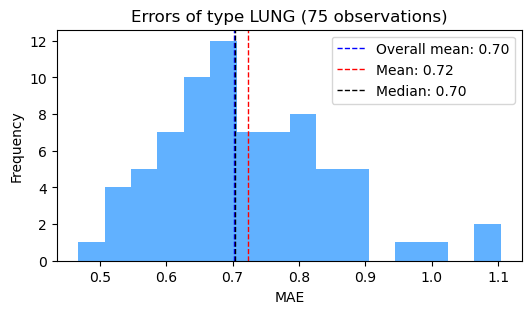

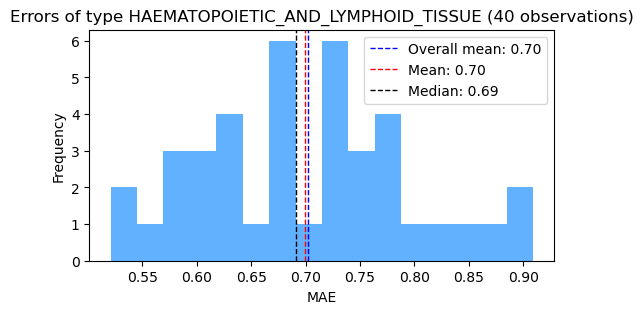

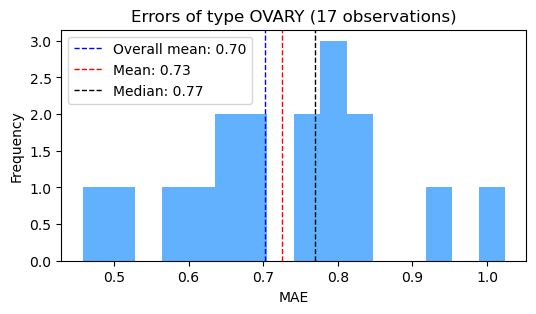

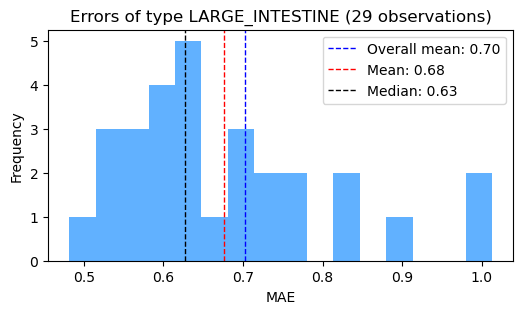

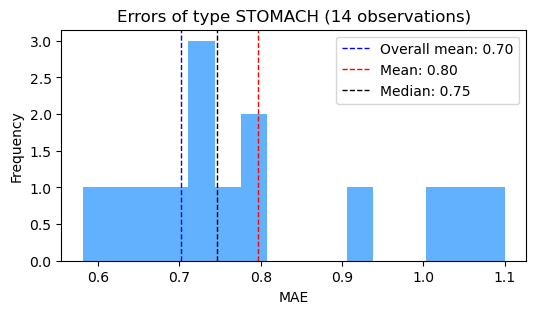

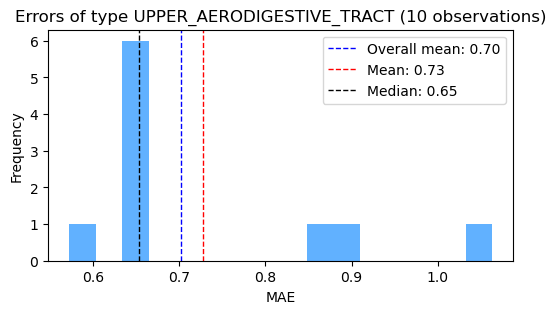

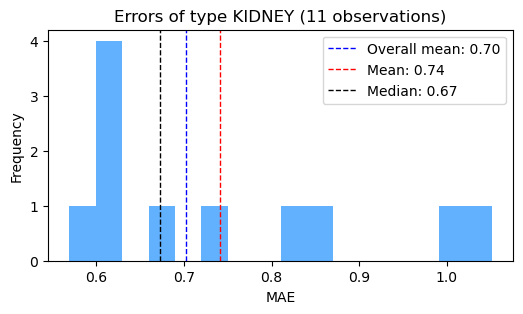

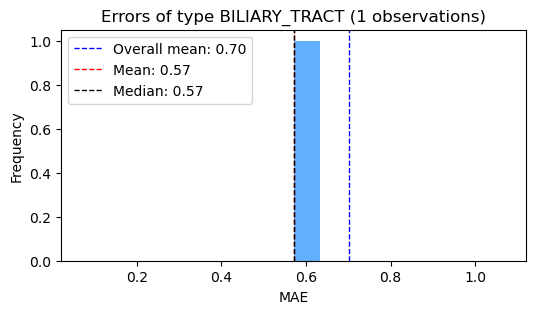

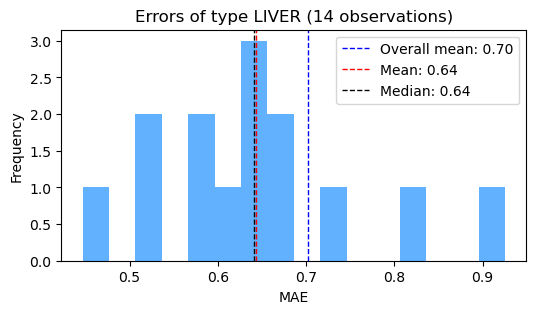

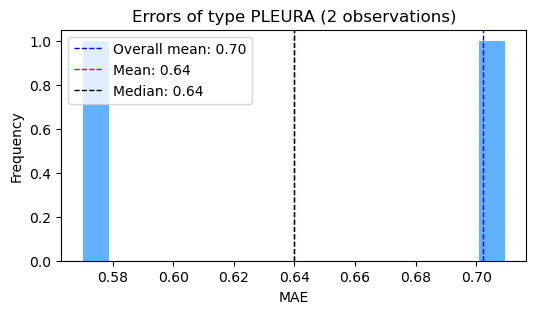

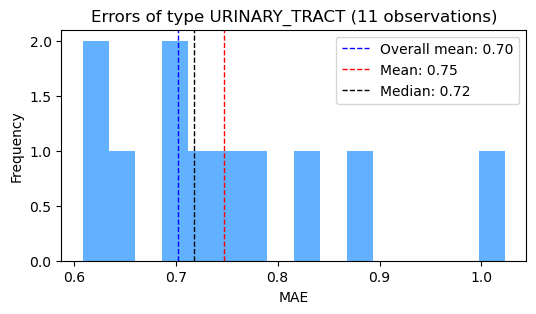

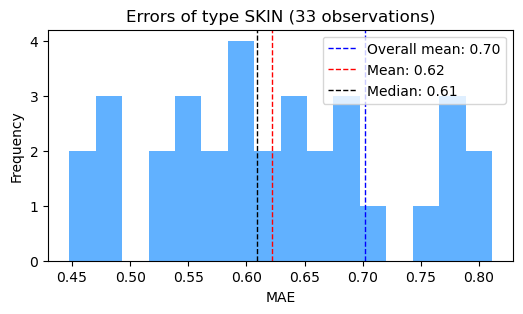

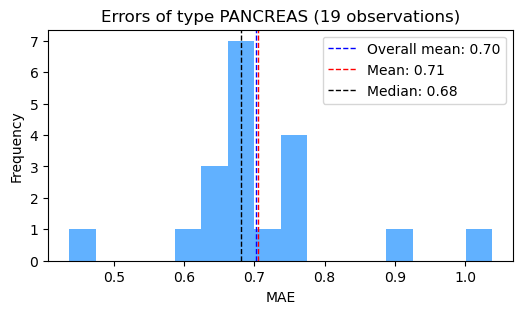

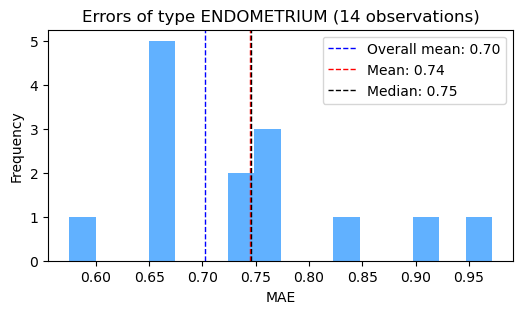

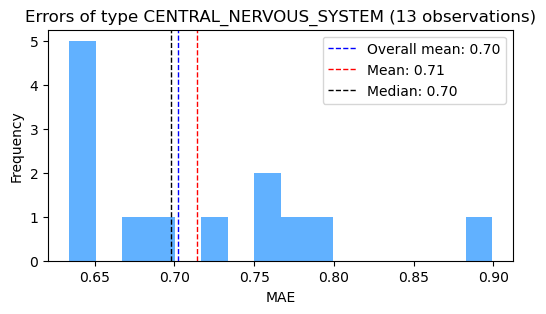

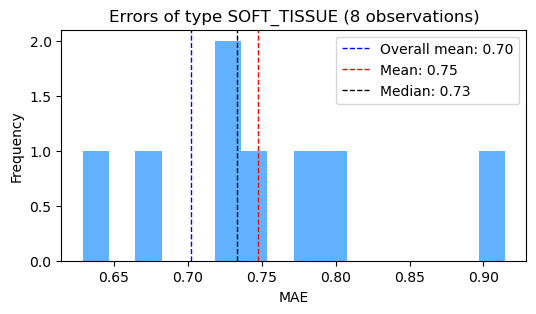

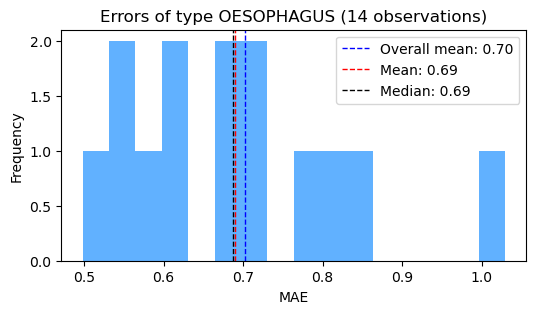

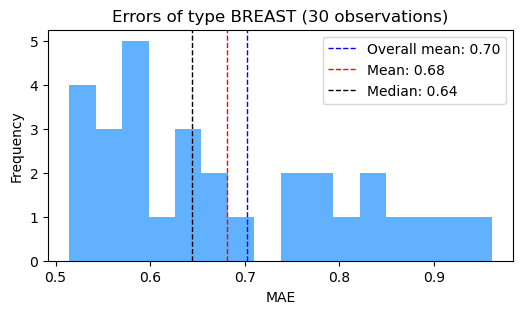

In [83]:
ovr_mean = loo_maes['error'].mean()

for t in tissues:
    subset = loo_maes[loo_maes['level_1'] == t]['error']

    mean_value = subset.mean()
    median_value = subset.median()
        
    plt.figure(figsize=(6, 3))
    plt.hist(subset, bins=16, alpha=0.7, color='dodgerblue')
    plt.axvline(ovr_mean, color='blue', linestyle='dashed', linewidth=1, label=f'Overall mean: {ovr_mean:.2f}')
    plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
    plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')
    plt.xlabel('MAE')
    plt.ylabel('Frequency')
    plt.title(f'Errors of type {t} ({len(subset)} observations)')
    plt.legend()
    plt.show()

In [84]:
tissue_errors = [loo_maes[loo_maes['level_1'] == t]['error'].mean() for t in tissues]
tissue_num = [len(loo_maes[loo_maes['level_1'] == t]['error']) for t in tissues]

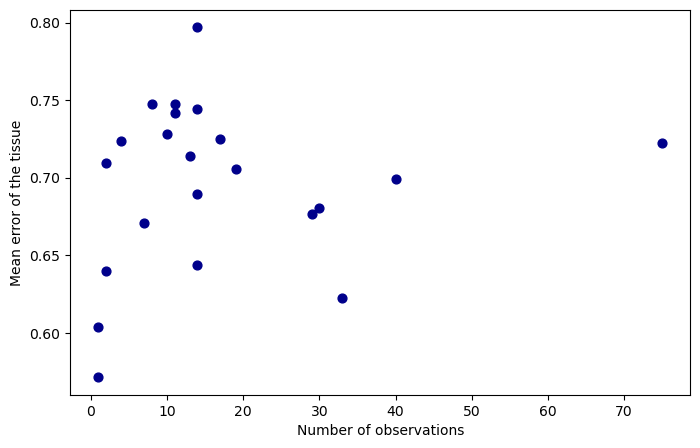

In [85]:
plt.figure(figsize=(8, 5))
plt.scatter(tissue_num, tissue_errors, color='darkblue', marker='o', s=40)

# Adding labels and title
plt.xlabel('Number of observations')
plt.ylabel('Mean error of the tissue')

# Display the plot
plt.show()

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21]),
 [Text(0, 0, 'PROSTATE'),
  Text(1, 0, 'HAEMATOPOIETIC_AND_LYMPHOID_TISSUE'),
  Text(2, 0, 'KIDNEY'),
  Text(3, 0, 'THYROID'),
  Text(4, 0, 'SKIN'),
  Text(5, 0, 'CENTRAL_NERVOUS_SYSTEM'),
  Text(6, 0, 'SOFT_TISSUE'),
  Text(7, 0, 'OVARY'),
  Text(8, 0, 'LUNG'),
  Text(9, 0, 'BONE'),
  Text(10, 0, 'STOMACH'),
  Text(11, 0, 'PANCREAS'),
  Text(12, 0, 'BREAST'),
  Text(13, 0, 'UPPER_AERODIGESTIVE_TRACT'),
  Text(14, 0, 'LARGE_INTESTINE'),
  Text(15, 0, 'ENDOMETRIUM'),
  Text(16, 0, 'LIVER'),
  Text(17, 0, 'URINARY_TRACT'),
  Text(18, 0, 'OESOPHAGUS'),
  Text(19, 0, 'PLEURA'),
  Text(20, 0, 'AUTONOMIC_GANGLIA'),
  Text(21, 0, 'BILIARY_TRACT')])

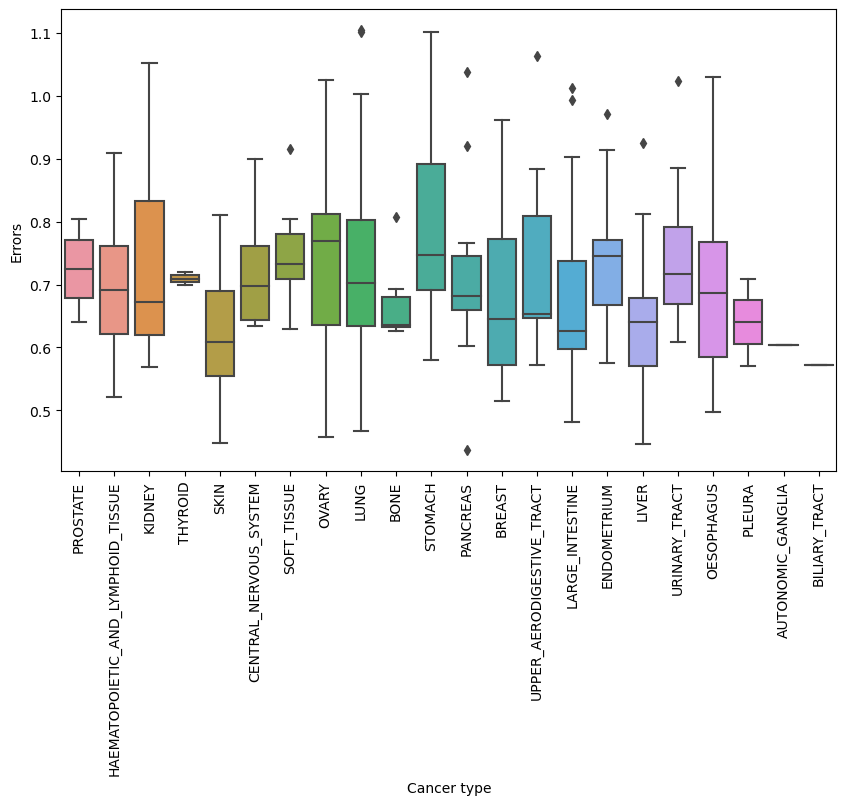

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='level_1', y='error', data=loo_maes)

plt.xlabel('Cancer type')
plt.ylabel('Errors')
plt.xticks(rotation=90)